# 02 - Feature Analysis, PCA & Outliers

## Dataset
Hotel Booking Demand dataset  
**Source:** [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

## Objective
Explore numerical and categorical features using scaling, distance and
similarity measures, feature analysis, PCA, and outlier detection.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("hotel_bookings.csv")
df.shape

(119390, 32)

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [5]:
print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [6]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

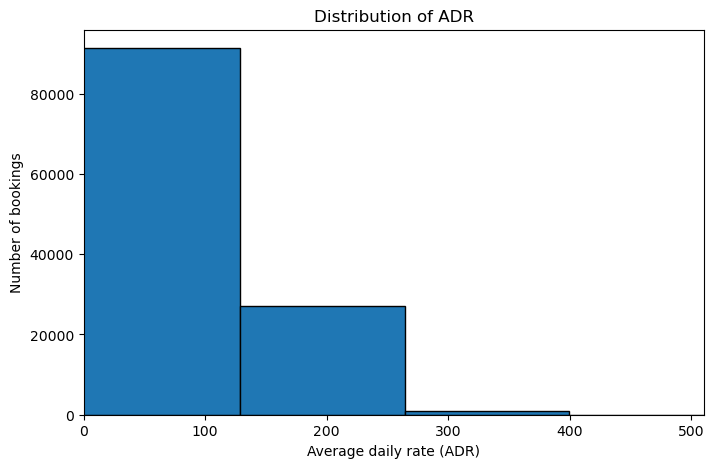

In [31]:
# TASK 1 - adr and arrival_date_week_number

plt.figure(figsize=(8, 5))
plt.hist(df["adr"].dropna(), bins=40, edgecolor="black")
plt.xlim(0, 510)  # show only ADR values from 0 to 500 on the x-axis
plt.title("Distribution of ADR")
plt.xlabel("Average daily rate (ADR)")
plt.ylabel("Number of bookings")
plt.show()

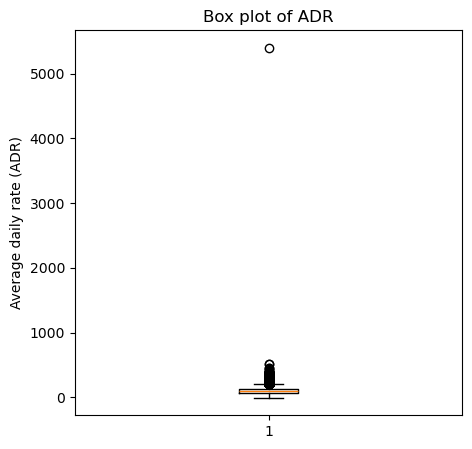

In [8]:
plt.figure(figsize=(5, 5))
plt.boxplot(df["adr"].dropna())
plt.title("Box plot of ADR")
plt.ylabel("Average daily rate (ADR)")
plt.show()

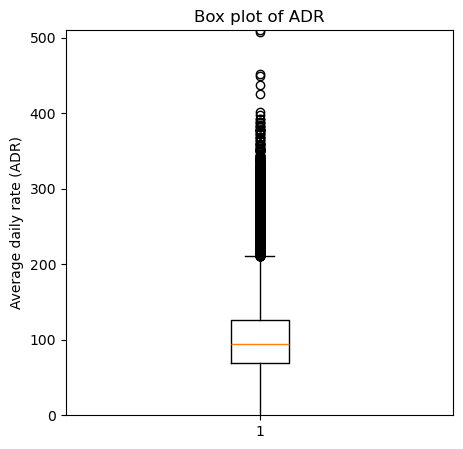

5400.0
48515     5400.00
111403     510.00
15083      508.00
103912     451.50
13142      450.00
13391      437.00
39155      426.25
39568      402.00
39118      397.38
13323      392.00
Name: adr, dtype: float64


In [9]:
plt.figure(figsize=(5, 5))
plt.boxplot(df["adr"].dropna())
plt.ylim(0, 510)
plt.title("Box plot of ADR")
plt.ylabel("Average daily rate (ADR)")
plt.show()


print(df["adr"].max())
print(df["adr"].nlargest(10))

In [10]:
adr = df["adr"].dropna()

Q1 = adr.quantile(0.25)
Q3 = adr.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["adr"] < lower_bound) | (df["adr"] > upper_bound)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers[["adr"]])  # row index and ADR value of every flagged booking

Q1: 69.29
Q3: 126.0
IQR: 56.709999999999994
Lower bound: -15.774999999999991
Upper bound: 211.065
Number of outliers: 3793


,adr
140,225.00
303,213.75
396,230.67
412,216.13
523,249.00
...,...
119251,235.00
119289,236.33
119339,229.00
119365,266.75


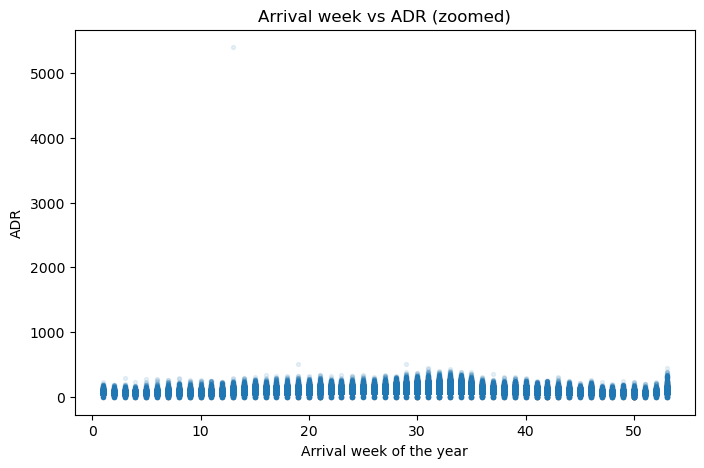

In [11]:
data = df[["arrival_date_week_number", "adr"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(data["arrival_date_week_number"], data["adr"], alpha=0.1, s=8)
plt.xlabel("Arrival week of the year")
plt.ylabel("ADR")
plt.title("Arrival week vs ADR (zoomed)")
plt.show()

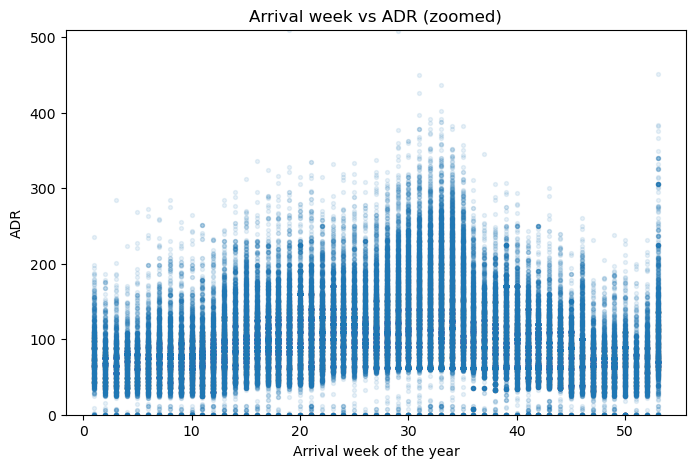

In [12]:
data = df[["arrival_date_week_number", "adr"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(data["arrival_date_week_number"], data["adr"], alpha=0.1, s=8)
plt.ylim(0, 510)
plt.xlabel("Arrival week of the year")
plt.ylabel("ADR")
plt.title("Arrival week vs ADR (zoomed)")
plt.show()

ADR varies widely within every arrival week. The scatter plot does not show a consistent positive or negative relationship between arrival week and ADR

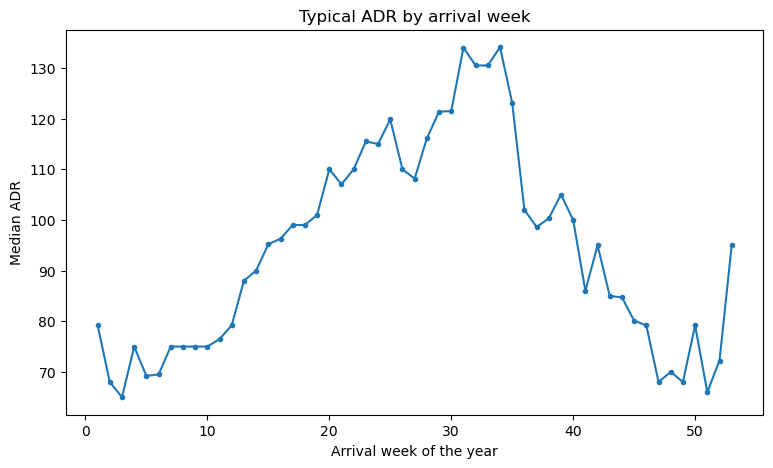

In [13]:
weekly_median = df.groupby("arrival_date_week_number")["adr"].median()

plt.figure(figsize=(9, 5))
plt.plot(weekly_median.index, weekly_median.values, marker="o", markersize=3)
plt.xlabel("Arrival week of the year")
plt.ylabel("Median ADR")
plt.title("Typical ADR by arrival week")
plt.show()

In [14]:
#TASK 2

x = df["lead_time"].dropna()

log_x = np.log(x + 1) #lead time starts with 0
minmax_x = (x - x.min()) / (x.max() - x.min())
zscore_x = (x - x.mean()) / x.std() #moves the mean to 0 and makes the standard deviation 1.

results = pd.DataFrame({
    "Before (original)": x.agg(["min", "max", "mean", "std"]),
    "Log(x)": log_x.agg(["min", "max", "mean", "std"]),
    "Min-Max": minmax_x.agg(["min", "max", "mean", "std"]),
    "Z-score": zscore_x.agg(["min", "max", "mean", "std"])
}).T

display(results.round(3))

,min,max,mean,std
Before (original),0.000,737.000,104.011,106.863
Log(x + 1),0.000,6.604,3.840,1.610
Min-Max,0.000,1.000,0.141,0.145
Z-score,-0.973,5.923,0.000,1.000


In [15]:
#TASK 3
df["total_nights"] = (
    df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
)

numeric_cols = ["lead_time", "adr", "adults",
                "total_nights", "total_of_special_requests"]

category_cols = ["hotel", "meal", "market_segment", "customer_type"]

sample = df.dropna(subset=numeric_cols + category_cols).sample(
    n=10, random_state=42
)

display(sample[numeric_cols + category_cols])

,lead_time,adr,adults,total_nights,total_of_special_requests,hotel,meal,market_segment,customer_type
30946,203,66.80,2,7,0,Resort Hotel,BB,Direct,Transient
40207,82,76.50,2,3,0,City Hotel,BB,Online TA,Transient
103708,25,60.00,3,3,1,City Hotel,BB,Offline TA/TO,Transient-Party
85144,1,95.00,1,1,0,City Hotel,BB,Online TA,Transient-Party
109991,70,108.00,2,4,0,City Hotel,SC,Online TA,Transient
110622,170,130.50,2,3,0,City Hotel,BB,Online TA,Transient
47790,21,85.00,1,1,0,City Hotel,BB,Online TA,Transient-Party
44992,102,109.00,2,2,0,City Hotel,HB,Offline TA/TO,Transient-Party
30528,55,67.44,2,7,0,Resort Hotel,HB,Online TA,Transient
16886,222,80.00,2,2,0,Resort Hotel,HB,Groups,Transient


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(sample[numeric_cols])

print("Shape of X:", X.shape)  

Shape of X: (10, 5)


In [17]:
sample.index = [f"Booking {i}" for i in range(1, 11)]

display(sample[numeric_cols + category_cols])

,lead_time,adr,adults,total_nights,total_of_special_requests,hotel,meal,market_segment,customer_type
Booking 1,203,66.80,2,7,0,Resort Hotel,BB,Direct,Transient
Booking 2,82,76.50,2,3,0,City Hotel,BB,Online TA,Transient
Booking 3,25,60.00,3,3,1,City Hotel,BB,Offline TA/TO,Transient-Party
Booking 4,1,95.00,1,1,0,City Hotel,BB,Online TA,Transient-Party
Booking 5,70,108.00,2,4,0,City Hotel,SC,Online TA,Transient
Booking 6,170,130.50,2,3,0,City Hotel,BB,Online TA,Transient
Booking 7,21,85.00,1,1,0,City Hotel,BB,Online TA,Transient-Party
Booking 8,102,109.00,2,2,0,City Hotel,HB,Offline TA/TO,Transient-Party
Booking 9,55,67.44,2,7,0,Resort Hotel,HB,Online TA,Transient
Booking 10,222,80.00,2,2,0,Resort Hotel,HB,Groups,Transient


In [18]:
from scipy.spatial.distance import pdist, squareform

euclidean = squareform(pdist(X, metric="euclidean"))
manhattan = squareform(pdist(X, metric="cityblock"))
minkowski = squareform(pdist(X, metric="minkowski", p=3))

labels = sample.index  # original dataframe row indices

display(pd.DataFrame(euclidean, index=labels, columns=labels).round(2))
display(pd.DataFrame(manhattan, index=labels, columns=labels).round(2))
display(pd.DataFrame(minkowski, index=labels, columns=labels).round(2))

,Booking 1,Booking 2,Booking 3,Booking 4,Booking 5,Booking 6,Booking 7,Booking 8,Booking 9,Booking 10
Booking 1,0.00,2.58,4.92,4.60,3.01,3.59,4.33,3.42,1.99,2.53
Booking 2,2.58,0.00,3.97,2.52,1.56,2.79,2.29,1.62,2.03,1.96
Booking 3,4.92,3.97,0.00,5.35,4.50,5.41,5.22,4.60,4.32,4.77
Booking 4,4.60,2.52,5.35,0.00,2.61,3.51,0.54,2.44,3.77,3.61
Booking 5,3.01,1.56,4.50,2.61,0.00,1.78,2.68,1.07,2.41,2.62
Booking 6,3.59,2.79,5.41,3.51,1.78,0.00,3.60,1.45,3.86,2.51
Booking 7,4.33,2.29,5.22,0.54,2.68,3.60,0.00,2.48,3.59,3.33
Booking 8,3.42,1.62,4.60,2.44,1.07,1.45,2.48,0.00,3.18,2.11
Booking 9,1.99,2.03,4.32,3.77,2.41,3.86,3.59,3.18,0.00,3.37
Booking 10,2.53,1.96,4.77,3.61,2.62,2.51,3.33,2.11,3.37,0.00


,Booking 1,Booking 2,Booking 3,Booking 4,Booking 5,Booking 6,Booking 7,Booking 8,Booking 9,Booking 10
Booking 1,0.00,4.03,9.86,8.82,5.18,5.38,8.09,5.77,2.02,3.31
Booking 2,4.03,0.00,6.73,4.79,2.12,3.72,4.05,2.28,2.74,2.54
Booking 3,9.86,6.73,0.00,9.98,8.53,10.45,9.25,9.01,7.89,9.27
Booking 4,8.82,4.79,9.98,0.00,4.86,6.77,0.74,4.36,6.80,6.02
Booking 5,5.18,2.12,8.53,4.86,0.00,2.89,5.06,1.45,3.56,4.33
Booking 6,5.38,3.72,10.45,6.77,2.89,0.00,6.97,2.41,6.45,3.55
Booking 7,8.09,4.05,9.25,0.74,5.06,6.97,0.00,4.56,6.06,5.29
Booking 8,5.77,2.28,9.01,4.36,1.45,2.41,4.56,0.00,5.02,2.98
Booking 9,2.02,2.74,7.89,6.80,3.56,6.45,6.06,5.02,0.00,5.28
Booking 10,3.31,2.54,9.27,6.02,4.33,3.55,5.29,2.98,5.28,0.00


,Booking 1,Booking 2,Booking 3,Booking 4,Booking 5,Booking 6,Booking 7,Booking 8,Booking 9,Booking 10
Booking 1,0.00,2.28,4.01,3.78,2.52,3.24,3.60,2.91,1.99,2.45
Booking 2,2.28,0.00,3.54,2.10,1.49,2.61,2.00,1.54,1.96,1.90
Booking 3,4.01,3.54,0.00,4.54,3.81,4.43,4.49,3.84,3.71,3.98
Booking 4,3.78,2.10,4.54,0.00,2.19,2.87,0.50,2.10,3.24,3.22
Booking 5,2.52,1.49,3.81,2.19,0.00,1.55,2.23,1.00,2.15,2.28
Booking 6,3.24,2.61,4.43,2.87,1.55,0.00,2.93,1.24,3.33,2.39
Booking 7,3.60,2.00,4.49,0.50,2.23,2.93,0.00,2.10,3.18,2.98
Booking 8,2.91,1.54,3.84,2.10,1.00,1.24,2.10,0.00,2.81,1.89
Booking 9,1.99,1.96,3.71,3.24,2.15,3.33,3.18,2.81,0.00,2.97
Booking 10,2.45,1.90,3.98,3.22,2.28,2.39,2.98,1.89,2.97,0.00


In [19]:
from sklearn.metrics.pairwise import cosine_similarity

cosine = cosine_similarity(X)

display(pd.DataFrame(cosine, index=labels, columns=labels).round(2))

,Booking 1,Booking 2,Booking 3,Booking 4,Booking 5,Booking 6,Booking 7,Booking 8,Booking 9,Booking 10
Booking 1,1.00,0.08,-0.10,-0.71,-0.23,-0.11,-0.61,-0.58,0.65,0.38
Booking 2,0.08,1.00,0.09,0.01,-0.44,-0.68,0.13,-0.35,0.33,0.10
Booking 3,-0.10,0.09,1.00,-0.36,-0.35,-0.46,-0.35,-0.39,0.10,-0.22
Booking 4,-0.71,0.01,-0.36,1.00,0.06,-0.12,0.98,0.24,-0.36,-0.39
Booking 5,-0.23,-0.44,-0.35,0.06,1.00,0.64,-0.14,0.60,0.02,-0.47
Booking 6,-0.11,-0.68,-0.46,-0.12,0.64,1.00,-0.25,0.82,-0.53,0.28
Booking 7,-0.61,0.13,-0.35,0.98,-0.14,-0.25,1.00,0.10,-0.32,-0.27
Booking 8,-0.58,-0.35,-0.39,0.24,0.60,0.82,0.10,1.00,-0.75,0.15
Booking 9,0.65,0.33,0.10,-0.36,0.02,-0.53,-0.32,-0.75,1.00,-0.39
Booking 10,0.38,0.10,-0.22,-0.39,-0.47,0.28,-0.27,0.15,-0.39,1.00


In [20]:
import pandas as pd

sample = sample.copy()
sample.index = [f"Booking {i}" for i in range(1, 11)]

category_cols = ["hotel", "meal", "market_segment", "customer_type"]

def jaccard(list1, list2):
    intersection = len(set(list1) & set(list2))
    union = len(set(list1) | set(list2))
    return intersection / union


In [21]:
booking_categories = []

for _, row in sample.iterrows():
    values = [f"{col}={row[col]}" for col in category_cols]
    booking_categories.append(values)


In [22]:
jaccard_table = pd.DataFrame(
    index=sample.index,
    columns=sample.index,
    dtype=float
)

for i in range(10):
    for j in range(10):
        jaccard_table.iloc[i, j] = jaccard(
            booking_categories[i],
            booking_categories[j]
        )

display(jaccard_table.round(2))

# Find the most similar pair, excluding a booking compared with itself
best_score = -1
best_pair = None

for i in range(10):
    for j in range(i + 1, 10):
        score = jaccard_table.iloc[i, j]

        if score > best_score:
            best_score = score
            best_pair = (sample.index[i], sample.index[j])

print("Most similar pair:", best_pair)
print("Jaccard similarity:", best_score)

,Booking 1,Booking 2,Booking 3,Booking 4,Booking 5,Booking 6,Booking 7,Booking 8,Booking 9,Booking 10
Booking 1,1.00,0.33,0.14,0.14,0.14,0.33,0.14,0.00,0.33,0.33
Booking 2,0.33,1.00,0.33,0.60,0.60,1.00,0.60,0.14,0.33,0.14
Booking 3,0.14,0.33,1.00,0.60,0.14,0.33,0.60,0.60,0.00,0.00
Booking 4,0.14,0.60,0.60,1.00,0.33,0.60,1.00,0.33,0.14,0.00
Booking 5,0.14,0.60,0.14,0.33,1.00,0.60,0.33,0.14,0.33,0.14
Booking 6,0.33,1.00,0.33,0.60,0.60,1.00,0.60,0.14,0.33,0.14
Booking 7,0.14,0.60,0.60,1.00,0.33,0.60,1.00,0.33,0.14,0.00
Booking 8,0.00,0.14,0.60,0.33,0.14,0.14,0.33,1.00,0.14,0.14
Booking 9,0.33,0.33,0.00,0.14,0.33,0.33,0.14,0.14,1.00,0.60
Booking 10,0.33,0.14,0.00,0.00,0.14,0.14,0.00,0.14,0.60,1.00


Most similar pair: ('Booking 2', 'Booking 6')
Jaccard similarity: 1.0


In [23]:
#TASK 4
from sklearn.feature_selection import mutual_info_classif

target = "is_canceled"

num_cols = df.select_dtypes(include="number").columns.drop(
    [target, "agent", "company"], errors="ignore"
)

X = df[num_cols].copy()
y = df[target]

# MI cannot work with missing values, so i fill each column with its median
X = X.dropna(axis=1, how="all")
X = X.fillna(X.median())
X = X.loc[:, X.nunique() > 1]

corr = X.corrwith(y)
mi = mutual_info_classif(X, y)

results = pd.DataFrame({
    "Pearson": corr,
    "Absolute Pearson": corr.abs(),
    "MI": mi
})

results["Pearson rank"] = results["Absolute Pearson"].rank(
    ascending=False, method="min"
).astype(int)

results["MI rank"] = results["MI"].rank(
    ascending=False, method="min"
).astype(int)

results["Rank difference"] = (
    results["Pearson rank"] - results["MI rank"]
).abs()

display(results.sort_values("Pearson rank").round(3))
display(results.sort_values("MI rank").round(3))
display(results.sort_values("Rank difference", ascending=False).head(5).round(3))

,Pearson,Absolute Pearson,MI,Pearson rank,MI rank,Rank difference
lead_time,0.293,0.293,0.083,1,1,0
total_of_special_requests,-0.235,0.235,0.038,2,4,2
required_car_parking_spaces,-0.195,0.195,0.033,3,5,2
booking_changes,-0.144,0.144,0.016,4,6,2
previous_cancellations,0.110,0.110,0.042,5,3,2
is_repeated_guest,-0.085,0.085,0.004,6,15,9
adults,0.060,0.060,0.008,7,11,4
previous_bookings_not_canceled,-0.057,0.057,0.010,8,9,1
days_in_waiting_list,0.054,0.054,0.014,9,7,2
adr,0.048,0.048,0.081,10,2,8


,Pearson,Absolute Pearson,MI,Pearson rank,MI rank,Rank difference
lead_time,0.293,0.293,0.083,1,1,0
adr,0.048,0.048,0.081,10,2,8
previous_cancellations,0.110,0.110,0.042,5,3,2
total_of_special_requests,-0.235,0.235,0.038,2,4,2
required_car_parking_spaces,-0.195,0.195,0.033,3,5,2
booking_changes,-0.144,0.144,0.016,4,6,2
days_in_waiting_list,0.054,0.054,0.014,9,7,2
total_nights,0.018,0.018,0.010,13,8,5
previous_bookings_not_canceled,-0.057,0.057,0.010,8,9,1
stays_in_week_nights,0.025,0.025,0.009,12,10,2


,Pearson,Absolute Pearson,MI,Pearson rank,MI rank,Rank difference
is_repeated_guest,-0.085,0.085,0.004,6,15,9
adr,0.048,0.048,0.081,10,2,8
babies,-0.032,0.032,0.000,11,18,7
stays_in_weekend_nights,-0.002,0.002,0.006,18,12,6
total_nights,0.018,0.018,0.010,13,8,5


In [24]:
#TASK 5
from sklearn.feature_selection import chi2
from sklearn.ensemble import RandomForestClassifier
y = df["is_canceled"]
# These columns reveal the final outcome or act as identifiers
exclude = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date",
    "agent",
    "company"
]

features = df.drop(columns=exclude, errors="ignore").copy()

# Separate categorical and numeric columns
cat_cols = features.select_dtypes(include=["object", "category"]).columns
num_cols = features.select_dtypes(include="number").columns

# Turn categories into 0/1 columns, for example hotel_City Hotel
X_cat = pd.get_dummies(
    features[cat_cols].fillna("Missing"),
    dtype=int
)

# 1. Chi-square on categorical features
chi_scores, p_values = chi2(X_cat, y)

chi_results = pd.DataFrame({
    "Feature": X_cat.columns,
    "Chi-square score": chi_scores,
    "p-value": p_values
}).sort_values("Chi-square score", ascending=False)

print("Top 5 from Chi-square:")
display(chi_results.head(5).round(3))


# Prepare numeric columns and combine them with the 0/1 category columns
X_num = features[num_cols].copy()
X_num = X_num.dropna(axis=1, how="all")
X_num = X_num.fillna(X_num.median())

X_all = pd.concat([X_num, X_cat], axis=1)
# 2. Embedded method: importance from a Random Forest
forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)
forest.fit(X_all, y)

rf_results = pd.DataFrame({
    "Feature": X_all.columns,
    "RF importance": forest.feature_importances_
}).sort_values("RF importance", ascending=False)

print("Top 5 from Random Forest:")
display(rf_results.head(5).round(3))

# Features that appear in both top-5 lists
overlap = set(chi_results.head(5)["Feature"]) & set(rf_results.head(5)["Feature"])
print("Features in both top 5:", overlap if overlap else "None")

Top 5 from Chi-square:


,Feature,Chi-square score,p-value
233,deposit_type_Non Refund,24293.423,0.0
155,country_PRT,7998.832,0.0
201,market_segment_Groups,4901.439,0.0
232,deposit_type_No Deposit,3368.650,0.0
200,market_segment_Direct,2545.320,0.0


Top 5 from Random Forest:


,Feature,RF importance
251,deposit_type_Non Refund,0.139
250,deposit_type_No Deposit,0.130
173,country_PRT,0.115
0,lead_time,0.083
16,total_of_special_requests,0.061


Features in both top 5: {'deposit_type_No Deposit', 'deposit_type_Non Refund', 'country_PRT'}


In [25]:
#TASK 6
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [26]:
# Select numeric feature - we exclude the target and identifier columns
num_cols = df.select_dtypes(include="number").columns.drop(
    ["is_canceled", "agent", "company"], errors="ignore"
)

X = df[num_cols].copy()
X = X.dropna(axis=1, how="all")
X = X.fillna(X.median())
X = X.loc[:, X.nunique() > 1]


X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)
X.shape

(119390, 18)

Minimum components for at least 80% variance: 12
Variance retained: 0.844


,Component,Explained variance ratio,Cumulative variance
0,1,0.147,0.147
1,2,0.095,0.242
2,3,0.088,0.331
3,4,0.080,0.410
4,5,0.064,0.475
5,6,0.060,0.535
6,7,0.058,0.592
7,8,0.055,0.647
8,9,0.053,0.700
9,10,0.051,0.751


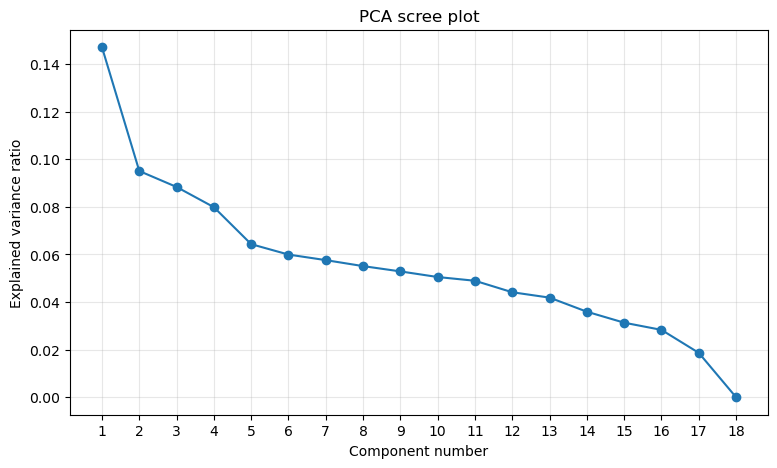

In [27]:
# First component count that reaches at least 80%
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

n_components_80 = np.argmax(cumulative >= 0.80) + 1
print("Minimum components for at least 80% variance:", n_components_80)
print("Variance retained:", round(cumulative[n_components_80 - 1], 3))

pca_results = pd.DataFrame({
    "Component": np.arange(1, len(explained) + 1),
    "Explained variance ratio": explained,
    "Cumulative variance": cumulative
})

display(pca_results.round(3))
# Scree plot
plt.figure(figsize=(9, 5))
plt.plot(pca_results["Component"], explained, marker="o")
plt.xlabel("Component number")
plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot")
plt.xticks(pca_results["Component"])
plt.grid(alpha=0.3)
plt.show()

PCA reduced the 18 numeric attributes to 12 components while retaining 84.4% of their total variation

In [28]:
# TASK 7
#X is the cleaned numeric table from Task 6

sample_indices = X.sample(10, random_state=42).index
sample_positions = X.index.get_indexer(sample_indices)
sample = X_scaled[sample_positions]

names = [f"Row {i}" for i in sample_indices]

gamma = 0.5

# Linear kernel: dot product between every pair of rows
K_linear = sample @ sample.T

# Squared Euclidean distance between every pair
sq_dists = (
    np.sum(sample**2, axis=1)[:, None]
    + np.sum(sample**2, axis=1)[None, :]
    - 2 * sample @ sample.T
)
sq_dists = np.maximum(sq_dists, 0)  # Avoid tiny negative numbers from rounding

# RBF kernel
K_rbf = np.exp(-gamma * sq_dists)

print("Linear kernel matrix:")
display(pd.DataFrame(K_linear, index=names, columns=names).round(3))

print("RBF kernel matrix:")
display(pd.DataFrame(K_rbf, index=names, columns=names).round(3))

# Find the most different pair, excluding comparisons of a row with itself
distances = sq_dists.copy()
np.fill_diagonal(distances, -1)
i, j = np.unravel_index(np.argmax(distances), distances.shape)

print("Most different pair:", names[i], "and", names[j])
print("Squared distance:", round(sq_dists[i, j], 3))
print("Linear kernel:", round(K_linear[i, j], 3))
print("RBF kernel:", round(K_rbf[i, j], 3))

Linear kernel matrix:


,Row 30946,Row 40207,Row 103708,Row 85144,Row 109991,Row 110622,Row 47790,Row 44992,Row 30528,Row 16886
Row 30946,45.603,-1.363,16.200,-6.396,-2.048,-5.351,-5.309,-1.335,14.390,0.378
Row 40207,-1.363,4.849,1.558,1.743,-2.254,-0.568,1.780,4.545,0.499,3.489
Row 103708,16.200,1.558,19.309,-5.578,-3.378,-0.638,-6.419,2.630,6.862,0.358
Row 85144,-6.396,1.743,-5.578,8.419,0.457,0.257,8.793,1.123,-4.828,0.126
Row 109991,-2.048,-2.254,-3.378,0.457,4.388,1.738,0.420,-2.969,0.118,-1.948
Row 110622,-5.351,-0.568,-0.638,0.257,1.738,6.174,-0.411,-0.873,-2.060,-1.644
Row 47790,-5.309,1.780,-6.419,8.793,0.420,-0.411,9.572,0.998,-5.094,0.476
Row 44992,-1.335,4.545,2.630,1.123,-2.969,-0.873,0.998,6.030,0.136,4.809
Row 30528,14.390,0.499,6.862,-4.828,0.118,-2.060,-5.094,0.136,10.016,-0.111
Row 16886,0.378,3.489,0.358,0.126,-1.948,-1.644,0.476,4.809,-0.111,6.594


RBF kernel matrix:


,Row 30946,Row 40207,Row 103708,Row 85144,Row 109991,Row 110622,Row 47790,Row 44992,Row 30528,Row 16886
Row 30946,1.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Row 40207,0.0,1.000,0.0,0.008,0.001,0.002,0.004,0.409,0.001,0.107
Row 103708,0.0,0.000,1.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Row 85144,0.0,0.008,0.0,1.000,0.003,0.001,0.817,0.002,0.000,0.001
Row 109991,0.0,0.001,0.0,0.003,1.000,0.029,0.001,0.000,0.001,0.001
Row 110622,0.0,0.002,0.0,0.001,0.029,1.000,0.000,0.001,0.000,0.000
Row 47790,0.0,0.004,0.0,0.817,0.001,0.000,1.000,0.001,0.000,0.000
Row 44992,0.0,0.409,0.0,0.002,0.000,0.001,0.001,1.000,0.000,0.222
Row 30528,0.0,0.001,0.0,0.000,0.001,0.000,0.000,0.000,1.000,0.000
Row 16886,0.0,0.107,0.0,0.001,0.001,0.000,0.000,0.222,0.000,1.000


Most different pair: Row 30946 and Row 85144
Squared distance: 66.814
Linear kernel: -6.396
RBF kernel: 0.0


In [29]:
#TASK 8
adr = df["adr"]
# 1. Z-score method
z = (adr - adr.mean()) / adr.std()
z_outliers = z.abs() > 3
# 2. IQR method
Q1 = adr.quantile(0.25)
Q3 = adr.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_outliers = (adr < lower) | (adr > upper)

print("Z-score outliers:", z_outliers.sum())
print("IQR outliers:", iqr_outliers.sum())

print("Z-score lower bound:", round(adr.mean() - 3 * adr.std(), 3))
print("Z-score upper bound:", round(adr.mean() + 3 * adr.std(), 3))
print("IQR lower bound:", round(lower, 3))
print("IQR upper bound:", round(upper, 3))

Z-score outliers: 1138
IQR outliers: 3793
Z-score lower bound: -49.776
Z-score upper bound: 253.438
IQR lower bound: -15.775
IQR upper bound: 211.065


In [30]:
# Show rows flagged by one method but not the other
comparison = pd.DataFrame({
    "adr": adr,
    "Z-score": z,
    "Z-score outlier": z_outliers,
    "IQR outlier": iqr_outliers
})

different = comparison[z_outliers != iqr_outliers]

print("Examples flagged by only one method:")
display(different.head(5).round(3))

# Inspect the booking with the highest ADR
print("Booking with the highest ADR:")
display(comparison.loc[[adr.idxmax()]].round(3))

Examples flagged by only one method:


,adr,Z-score,Z-score outlier,IQR outlier
140,225.00,2.437,False,True
303,213.75,2.215,False,True
396,230.67,2.549,False,True
412,216.13,2.262,False,True
523,249.00,2.912,False,True


Booking with the highest ADR:


,adr,Z-score,Z-score outlier,IQR outlier
48515,5400.0,104.84,True,True
